# Static dataset: inspection, preprocessing and EDA
Every number and chart below comes from the real file `TUANDROMD.csv`. After each figure, write 2-3 sentences of YOUR interpretation in the yellow cells (what pattern, why it matters for classification).

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config
from src.preprocessing.loaders import load_static
import json

## 1. Load and inspect

In [2]:
raw = pd.read_csv(config.STATIC_CSV, low_memory=False)
print(raw.shape)
raw.head()

(4465, 242)


,ACCESS_ALL_DOWNLOADS,ACCESS_CACHE_FILESYSTEM,ACCESS_CHECKIN_PROPERTIES,ACCESS_COARSE_LOCATION,ACCESS_COARSE_UPDATES,ACCESS_FINE_LOCATION,ACCESS_LOCATION_EXTRA_COMMANDS,ACCESS_MOCK_LOCATION,ACCESS_MTK_MMHW,ACCESS_NETWORK_STATE,...,Landroid/telephony/TelephonyManager;->getLine1Number,Landroid/telephony/TelephonyManager;->getNetworkOperator,Landroid/telephony/TelephonyManager;->getNetworkOperatorName,Landroid/telephony/TelephonyManager;->getNetworkCountryIso,Landroid/telephony/TelephonyManager;->getSimOperator,Landroid/telephony/TelephonyManager;->getSimOperatorName,Landroid/telephony/TelephonyManager;->getSimCountryIso,Landroid/telephony/TelephonyManager;->getSimSerialNumber,Lorg/apache/http/impl/client/DefaultHttpClient;->execute,Label
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,malware
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,malware
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,malware
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,malware
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,malware


In [3]:
print(raw.dtypes.value_counts())
print('Missing cells:', int(raw.isna().sum().sum()))
print('Duplicate rows:', int(raw.duplicated().sum()))

float64    241
str          1
Name: count, dtype: int64
Missing cells: 242
Duplicate rows: 3802


## 2. Cleaning (documented in the log)
Rows without a label, exact duplicates and non-numeric cells are handled in `src/preprocessing/loaders.py`.

In [4]:
bundle = load_static(config.STATIC_CSV)
print(json.dumps(bundle.log, indent=2))

{
  "source_file": "/home/aman-ajwa-fatima/Desktop/ForenSight-AI/datasets/static_analysis/TUANDROMD.csv",
  "label_column": "Label",
  "groups_available": false,
  "raw_label_values": {
    "malware": 3565,
    "goodware": 899,
    "nan": 1
  },
  "rows_loaded": 4465,
  "rows_dropped_missing_label": 1,
  "dtypes_before": {
    "float64": 241
  },
  "missing_cells_after_coercion": 0,
  "all_nan_columns_dropped": [],
  "duplicate_rows_removed": 3802,
  "rows_final": 662,
  "n_features": 241,
  "class_counts": {
    "benign": 531,
    "malware": 131
  }
}


## 3. Class distribution and imbalance

In [5]:
print(bundle.y.map({0:'benign',1:'malware'}).value_counts())
print(bundle.y.value_counts(normalize=True).round(3))

Label
benign     531
malware    131
Name: count, dtype: int64
Label
0    0.802
1    0.198
Name: proportion, dtype: float64


## 4. EDA figures

prevalence_figure


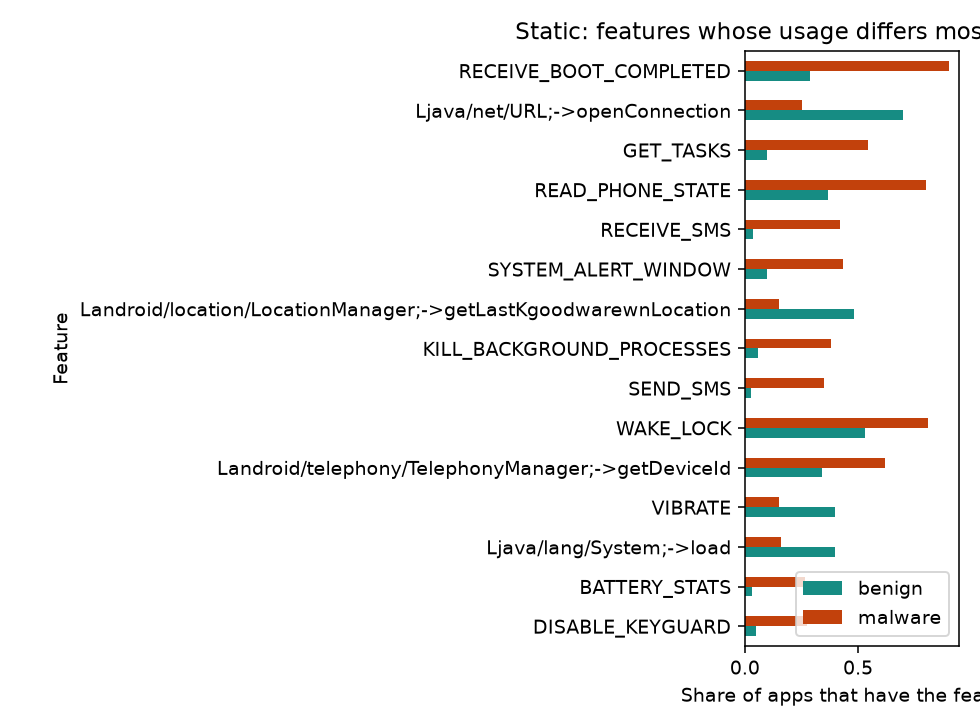

correlation_figure


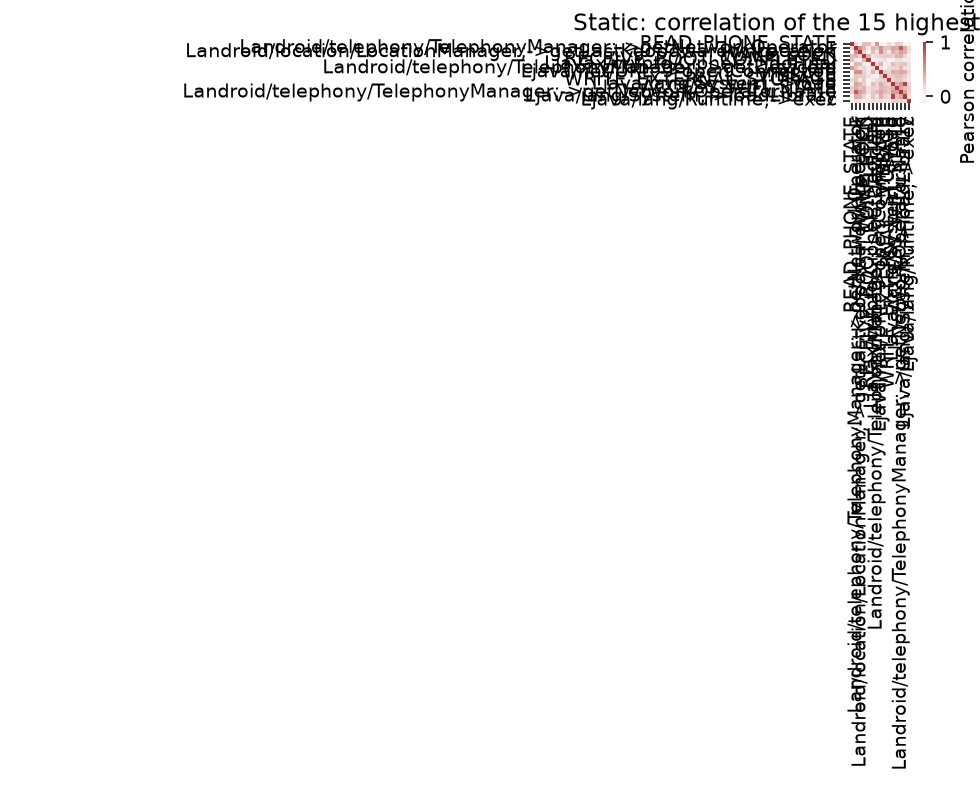

count_figure


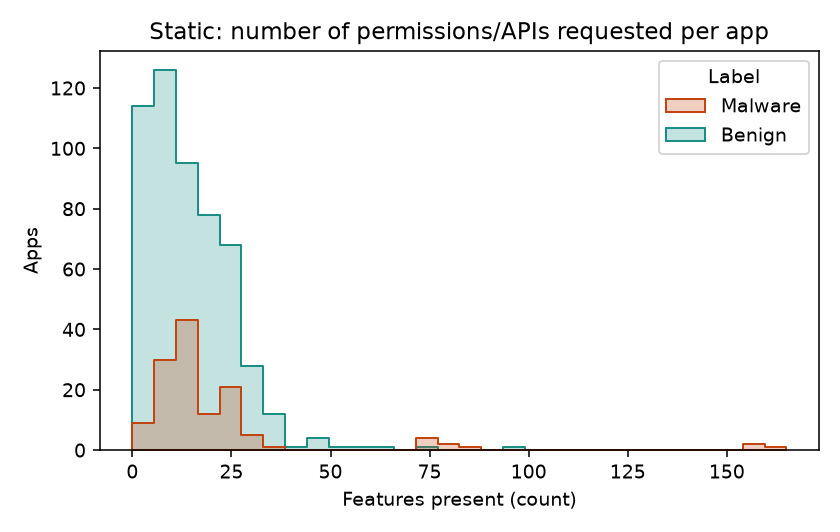

In [6]:
from src.evaluation import eda
summary = eda.eda_static(bundle)
for k, v in summary.items():
    if isinstance(v, str) and v.startswith('figures/'):
        print(k); display(Image(filename=str(config.ROOT / 'reports' / v)))

In [7]:
summary  # computed numbers behind the figures

{'class_distribution': ('figures/static_class_distribution.png',
  {'Benign': 531, 'Malware': 131}),
 'prevalence_figure': 'figures/static_feature_prevalence.png',
 'prevalence_top': {'RECEIVE_BOOT_COMPLETED': {'benign': 0.2862523540489642,
   'malware': 0.9007633587786259},
  'Ljava/net/URL;->openConnection': {'benign': 0.7005649717514124,
   'malware': 0.25190839694656486},
  'GET_TASKS': {'benign': 0.09981167608286252, 'malware': 0.5419847328244275},
  'READ_PHONE_STATE': {'benign': 0.3653483992467043,
   'malware': 0.8015267175572519},
  'RECEIVE_SMS': {'benign': 0.03389830508474576,
   'malware': 0.4198473282442748},
  'SYSTEM_ALERT_WINDOW': {'benign': 0.09792843691148775,
   'malware': 0.4351145038167939},
  'Landroid/location/LocationManager;->getLastKgoodwarewnLocation': {'benign': 0.4821092278719397,
   'malware': 0.15267175572519084},
  'KILL_BACKGROUND_PROCESSES': {'benign': 0.05649717514124294,
   'malware': 0.3816793893129771},
  'SEND_SMS': {'benign': 0.026365348399246705

**Your interpretation (class balance):** …

**Your interpretation (feature patterns):** …

**Leakage risks you noticed:** …